IsoVita smoke test on simulated data.

In [7]:
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import isovita as iso


@dataclass(frozen=True)
class SimScenario:
    gene_id: str
    label: str
    k: int
    assignment: tuple[int, ...]   # +1=A, -1=B, 0=unused
    kind: str
    amplitude: float = 2.0
    noise_sd: float = 0.18
    change_age: float | None = None
    window: tuple[float, float] | None = None


SCENARIOS = [
    SimScenario(
        "SIM_NULL", "Null K=3",
        3, (1, -1, 0), "null",
        amplitude=0.0,
    ),
    SimScenario(
        "SIM_K2_STEP", "K=2 pure step",
        2, (1, -1), "step",
        amplitude=2.2, change_age=35,
    ),
    SimScenario(
        "SIM_K3_UNUSED", "K=3 step + unused",
        3, (1, -1, 0), "step",
        amplitude=2.2, change_age=35,
    ),
    SimScenario(
        "SIM_K4_GROUP", "K=4 grouped step",
        4, (1, 1, -1, -1), "step",
        amplitude=2.2, change_age=35,
    ),
    SimScenario(
        "SIM_SMOOTH", "K=3 smooth",
        3, (1, -1, 0), "smooth",
        amplitude=1.4,
    ),
    SimScenario(
        "SIM_CURVED", "K=4 U-shaped",
        4, (1, 1, -1, 0), "u_shape",
        amplitude=1.7,
    ),
    SimScenario(
        "SIM_LOCAL_EARLY", "Localized 0–10",
        3, (1, -1, 0), "localized",
        amplitude=2.2, window=(0, 10),
    ),
    SimScenario(
        "SIM_LOCAL_MID", "Localized 20–40",
        4, (1, 1, -1, 0), "localized",
        amplitude=2.0, window=(20, 40),
    ),
    SimScenario(
        "SIM_MIXED", "Step + smooth",
        3, (1, -1, 0), "step_smooth",
        amplitude=1.8, change_age=30,
    ),
]

In [8]:
# compositional simulator
def _balance_direction(assignment):
    """Unit-norm zero-sum direction implied by A/B/unused assignment."""
    z = np.asarray(assignment, dtype=int)

    a = np.flatnonzero(z == 1)
    b = np.flatnonzero(z == -1)

    v = np.zeros(len(z), dtype=float)
    v[a] = 1.0 / len(a)
    v[b] = -1.0 / len(b)

    return v / np.linalg.norm(v)


def _trajectory(age, scenario):
    """Noise-free temporal signal h(age)."""
    age = np.asarray(age, dtype=float)

    if scenario.kind == "null":
        return np.zeros_like(age)

    if scenario.kind == "step":
        return np.where(age < scenario.change_age, -0.5, 0.5)

    if scenario.kind == "smooth":
        return np.tanh((age - 35.0) / 18.0)

    if scenario.kind == "u_shape":
        x = (age - 42.5) / 42.5
        h = x**2
        h = h - h.mean()
        return h / np.max(np.abs(h))

    if scenario.kind == "localized":
        left, right = scenario.window
        center = (left + right) / 2
        sd = (right - left) / 4

        h = np.exp(-0.5 * ((age - center) / sd) ** 2)
        h[(age < left) | (age >= right)] = 0.0

        # constant outside the target window
        return h - h.mean()

    if scenario.kind == "step_smooth":
        step = np.where(age < scenario.change_age, -0.4, 0.4)
        smooth = 0.35 * np.tanh((age - 45.0) / 20.0)
        return step + smooth

    raise ValueError(f"Unknown scenario kind: {scenario.kind}")


def _softmax(z):
    z = np.asarray(z, dtype=float)
    exp_z = np.exp(z - z.max(axis=1, keepdims=True))
    return exp_z / exp_z.sum(axis=1, keepdims=True)


def simulate_isovita_smoke_data(
    scenarios=SCENARIOS,
    n_samples=180,
    seed=20260918,
):
    rng = np.random.default_rng(seed)

    # Simple well-covered postnatal age design.
    ages = np.sort(rng.uniform(0, 85, n_samples))
    samples = np.array([f"S{i:03d}" for i in range(n_samples)])

    metadata = pd.DataFrame(
        {"age": ages},
        index=samples,
    )
    metadata.index.name = "sample"

    expression_rows = []
    global_metric_rows = []
    fraction_rows = []
    true_feature_rows = []
    truth_rows = []

    for s in scenarios:
        assignment = np.asarray(s.assignment)
        direction = _balance_direction(assignment)
        h = _trajectory(ages, s)

        # Mild unequal baseline usage across isoforms.
        baseline = np.linspace(0.25, -0.25, s.k)

        # Noise-free and noisy latent log-abundances.
        latent = (
            baseline[None, :]
            + s.amplitude * h[:, None] * direction[None, :]
        )

        noisy_latent = latent + rng.normal(
            0,
            s.noise_sd,
            size=(n_samples, s.k),
        )

        true_fraction = _softmax(latent)
        observed_fraction = _softmax(noisy_latent)

        # Arbitrary positive gene-level TPM.
        gene_total = rng.lognormal(
            mean=np.log(50),
            sigma=0.15,
            size=n_samples,
        )

        tx_ids = [
            f"{s.gene_id}_TX{i + 1}"
            for i in range(s.k)
        ]

        for j, tx in enumerate(tx_ids):
            expression_rows.append({
                "gene_id": s.gene_id,
                "transcript_id": tx,
                **dict(zip(
                    samples,
                    observed_fraction[:, j] * gene_total,
                )),
            })

            # Oracle effective-isoform set for first-pass testing.
            global_metric_rows.append({
                "gene_id": s.gene_id,
                "transcript_id": tx,
                "effective": True,
            })

            for i, sample in enumerate(samples):
                fraction_rows.append({
                    "gene_id": s.gene_id,
                    "sample": sample,
                    "age": ages[i],
                    "transcript_id": tx,
                    "fraction": observed_fraction[i, j],
                    "true_fraction": true_fraction[i, j],
                    "true_group": int(assignment[j]),
                })

        # Noise-free planted log(GM(A)/GM(B)).
        a = np.flatnonzero(assignment == 1)
        b = np.flatnonzero(assignment == -1)

        true_feature = (
            np.log(true_fraction[:, a]).mean(axis=1)
            - np.log(true_fraction[:, b]).mean(axis=1)
        )

        for i, sample in enumerate(samples):
            true_feature_rows.append({
                "gene_id": s.gene_id,
                "sample": sample,
                "age": ages[i],
                "true_feature": true_feature[i],
            })

        truth_rows.append({
            "gene_id": s.gene_id,
            "label": s.label,
            "kind": s.kind,
            "assignment": s.assignment,
            "change_age": s.change_age,
            "window": s.window,
        })

    return {
        "metadata": metadata,
        "expression": pd.DataFrame(expression_rows),
        "global_metrics": pd.DataFrame(global_metric_rows),
        "fractions": pd.DataFrame(fraction_rows),
        "true_feature": pd.DataFrame(true_feature_rows),
        "truth": pd.DataFrame(truth_rows),
    }

In [9]:
# run IsoVita
def run_isovita_smoke_test(
    sim,
    discrete_permutations=250,
    random_seed=17,
):
    metadata = sim["metadata"]
    sample_cols = metadata.index.tolist()

    # --------------------------------------------------------
    # 1. One feature per gene
    # --------------------------------------------------------
    balance_summary, balance_loadings, balance_feature_matrix = (
        iso.build_one_feature_per_gene(
            expression_df=sim["expression"],
            global_metrics=sim["global_metrics"],
            sample_cols=sample_cols,
            metadata=metadata,
            config=iso.BalanceConfig(),
        )
    )

    # --------------------------------------------------------
    # 2. Three parallel temporal branches
    # --------------------------------------------------------
    discrete = iso.run_discrete_feature_tests(
        balance_feature_matrix,
        metadata,
        config=iso.DiscreteConfig(
            n_permutations=discrete_permutations,
            random_seed=random_seed,
        ),
    )

    continuous = iso.run_continuous_feature_tests(
        balance_feature_matrix,
        metadata,
        config=iso.FeatureTestConfig(),
    )

    localized = iso.run_localized_feature_tests(
        balance_feature_matrix,
        metadata,
        windows=iso.WindowConfig(),
        config=iso.FeatureTestConfig(),
    )

    # --------------------------------------------------------
    # 3. Merge branch evidence
    # --------------------------------------------------------
    gene_summary = iso.summarize_gene_trajectories(
        balance_summary,
        discrete,
        continuous,
        localized,
    )

    (
        discrete_candidates,
        continuous_candidates,
        localized_candidates,
        final_features,
    ) = iso.select_final_gene_features(gene_summary)

    return {
        "balance_summary": balance_summary,
        "balance_loadings": balance_loadings,
        "balance_feature_matrix": balance_feature_matrix,
        "discrete": discrete,
        "continuous": continuous,
        "localized": localized,
        "gene_summary": gene_summary,
        "final_features": final_features,
    }

In [10]:
sim = simulate_isovita_smoke_data()
result = run_isovita_smoke_test(sim)

cols = [
    "gene_id",
    "group_A",
    "group_B",
    "unused_isoforms",
    "cosine_similarity",
    "pc1_explained_variance_ratio",
    "discrete_q_value",
    "discrete_change_age",
    "continuous_q_value",
    "best_window",
    "best_window_q_value",
    "trajectory_signature",
]

display(
    result["gene_summary"][cols]
    .sort_values("gene_id")
    .reset_index(drop=True)
)

,gene_id,group_A,group_B,unused_isoforms,cosine_similarity,pc1_explained_variance_ratio,discrete_q_value,discrete_change_age,continuous_q_value,best_window,best_window_q_value,trajectory_signature
0,SIM_CURVED,SIM_CURVED_TX3,SIM_CURVED_TX1|SIM_CURVED_TX2,SIM_CURVED_TX4,0.999775,0.999291,0.004482,74.051881,2.512655e-111,40-85,6.334852e-58,discrete+continuous+localized
1,SIM_K2_STEP,SIM_K2_STEP_TX2,SIM_K2_STEP_TX1,,1.000000,1.000000,0.004482,34.983397,8.250317e-57,20-40,4.941367e-09,discrete+continuous+localized
2,SIM_K3_UNUSED,SIM_K3_UNUSED_TX1,SIM_K3_UNUSED_TX2,SIM_K3_UNUSED_TX3,0.999975,0.999769,0.004482,34.983397,1.247690e-55,20-40,8.224025e-10,discrete+continuous+localized
3,SIM_K4_GROUP,SIM_K4_GROUP_TX3|SIM_K4_GROUP_TX4,SIM_K4_GROUP_TX1|SIM_K4_GROUP_TX2,,0.999845,0.998638,0.004482,34.983397,2.240655e-55,20-40,5.701085e-09,discrete+continuous+localized
4,SIM_LOCAL_EARLY,SIM_LOCAL_EARLY_TX1,SIM_LOCAL_EARLY_TX2,SIM_LOCAL_EARLY_TX3,0.997268,0.996323,0.004482,16.072770,1.782817e-27,0-10,6.722860e-06,discrete+continuous+localized
5,SIM_LOCAL_MID,SIM_LOCAL_MID_TX3,SIM_LOCAL_MID_TX1|SIM_LOCAL_MID_TX2,SIM_LOCAL_MID_TX4,0.999463,0.994844,0.004482,39.290803,1.634391e-19,20-40,1.695846e-15,discrete+continuous+localized
6,SIM_MIXED,SIM_MIXED_TX1,SIM_MIXED_TX2,SIM_MIXED_TX3,0.999998,0.999884,0.004482,30.051225,2.666264e-82,40-85,1.139583e-20,discrete+continuous+localized
7,SIM_NULL,SIM_NULL_TX3,SIM_NULL_TX1,SIM_NULL_TX2,0.974943,0.719904,0.083665,52.502530,1.132571e-01,40-85,1.445881e-01,not_selected
8,SIM_SMOOTH,SIM_SMOOTH_TX2,SIM_SMOOTH_TX1,SIM_SMOOTH_TX3,0.999923,0.999702,0.004482,37.585167,6.292801e-124,40-85,3.123529e-24,discrete+continuous+localized


In [11]:
def _true_groups(scenario):
    z = np.asarray(scenario.assignment)

    tx = [
        f"{scenario.gene_id}_TX{i + 1}"
        for i in range(scenario.k)
    ]

    return (
        [tx[i] for i in np.flatnonzero(z == 1)],
        [tx[i] for i in np.flatnonzero(z == -1)],
        [tx[i] for i in np.flatnonzero(z == 0)],
    )


def _short_tx_list(value, gene_id):
    if isinstance(value, str):
        value = [] if value == "" else value.split("|")

    short = [
        x.replace(f"{gene_id}_", "")
        for x in value
    ]

    return "|".join(short) if short else "—"


def plot_isovita_case(sim, result, scenario):
    gene = scenario.gene_id

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(14, 4.2),
        gridspec_kw={"width_ratios": [1.2, 1.2, 1.0]},
    )

    ax_frac, ax_feature, ax_summary = axes

    # ========================================================
    # A. Isoform fractions
    # ========================================================
    frac = sim["fractions"].query(
        "gene_id == @gene"
    )

    group_name = {
        1: "A",
        -1: "B",
        0: "unused",
    }

    for tx, sub in frac.groupby(
        "transcript_id",
        sort=False,
    ):
        sub = sub.sort_values("age")
        group = group_name[int(sub["true_group"].iloc[0])]

        line, = ax_frac.plot(
            sub["age"],
            sub["true_fraction"],
            lw=2,
            label=f"{tx.replace(gene + '_', '')} [{group}]",
        )

        ax_frac.scatter(
            sub["age"],
            sub["fraction"],
            s=10,
            alpha=0.30,
            color=line.get_color(),
        )

    ax_frac.set_title("A  Simulated isoform fractions")
    ax_frac.set_xlabel("Age")
    ax_frac.set_ylabel("Fraction")
    ax_frac.legend(
        fontsize=8,
        frameon=False,
    )

    # ========================================================
    # B. True versus learned gene feature
    # ========================================================
    truth_feature = (
        sim["true_feature"]
        .query("gene_id == @gene")
        .sort_values("age")
    )

    samples = truth_feature["sample"].tolist()

    learned = (
        result["balance_feature_matrix"]
        .loc[gene, samples]
        .to_numpy(dtype=float)
    )

    true = truth_feature["true_feature"].to_numpy(dtype=float)

    # A/B labels are sign-indeterminate.
    corr = np.corrcoef(learned, true)[0, 1]
    if np.isfinite(corr) and corr < 0:
        true = -true

    ax_feature.scatter(
        truth_feature["age"],
        learned,
        s=13,
        alpha=0.45,
        label="Learned feature",
    )

    ax_feature.plot(
        truth_feature["age"],
        true,
        lw=2.2,
        label="True latent feature (sign-aligned)",
    )

    if scenario.change_age is not None:
        ax_feature.axvline(
            scenario.change_age,
            ls=":",
            lw=1.5,
            label="True changepoint",
        )

    discrete_row = (
        result["discrete"]
        .set_index("gene_id")
        .loc[gene]
    )

    if bool(discrete_row["tested"]):
        ax_feature.axvline(
            discrete_row["best_change_age"],
            ls="--",
            lw=1.5,
            label="Estimated changepoint",
        )

    if scenario.window is not None:
        ax_feature.axvspan(
            scenario.window[0],
            scenario.window[1],
            alpha=0.08,
            label="True local window",
        )

    ax_feature.set_title("B  Condensed gene feature")
    ax_feature.set_xlabel("Age")
    ax_feature.set_ylabel("log GM(A) / GM(B)")
    ax_feature.legend(
        fontsize=8,
        frameon=False,
    )

    # ========================================================
    # C. Compact IsoVita summary
    # ========================================================
    balance_row = (
        result["balance_summary"]
        .set_index("gene_id")
        .loc[gene]
    )

    gene_row = (
        result["gene_summary"]
        .set_index("gene_id")
        .loc[gene]
    )

    loadings = (
        result["balance_loadings"]
        .query("gene_id == @gene")
        .set_index("transcript_id")
    )

    tx_order = [
        f"{gene}_TX{i + 1}"
        for i in range(scenario.k)
    ]

    learned_assignment = (
        loadings["balance_assignment"]
        .reindex(tx_order)
        .to_numpy(dtype=int)
    )

    true_assignment = np.asarray(scenario.assignment)

    if scenario.kind == "null":
        recovered = "n/a"
    else:
        recovered = (
            np.array_equal(
                learned_assignment,
                true_assignment,
            )
            or np.array_equal(
                learned_assignment,
                -true_assignment,
            )
        )

    true_a, true_b, true_unused = _true_groups(scenario)

    summary_text = (
        "Truth\n"
        f"  A: {_short_tx_list(true_a, gene)}\n"
        f"  B: {_short_tx_list(true_b, gene)}\n"
        f"  unused: {_short_tx_list(true_unused, gene)}\n"
        "\n"
        "Learned\n"
        f"  A: {_short_tx_list(balance_row['group_A'], gene)}\n"
        f"  B: {_short_tx_list(balance_row['group_B'], gene)}\n"
        f"  unused: {_short_tx_list(balance_row['unused_isoforms'], gene)}\n"
        f"  grouping recovered: {recovered}\n"
        f"  cosine: {balance_row['cosine_similarity']:.3f}\n"
        f"  PC1 variance: "
        f"{balance_row['pc1_explained_variance_ratio']:.3f}\n"
        "\n"
        "Branches\n"
        f"  discrete q: {gene_row['discrete_q_value']:.3g}\n"
        f"  change age: {gene_row['discrete_change_age']:.1f}\n"
        f"  continuous q: {gene_row['continuous_q_value']:.3g}\n"
        f"  best local q: {gene_row['best_window_q_value']:.3g}\n"
        f"  best window: {gene_row['best_window']}\n"
        "\n"
        "Signature\n"
        f"  {gene_row['trajectory_signature']}"
    )

    ax_summary.axis("off")
    ax_summary.text(
        0,
        1,
        summary_text,
        ha="left",
        va="top",
        family="monospace",
        fontsize=9,
    )
    ax_summary.set_title("C  IsoVita summary")

    fig.suptitle(
        f"{scenario.label}  ({gene})",
        fontweight="bold",
    )

    fig.tight_layout()

    return fig

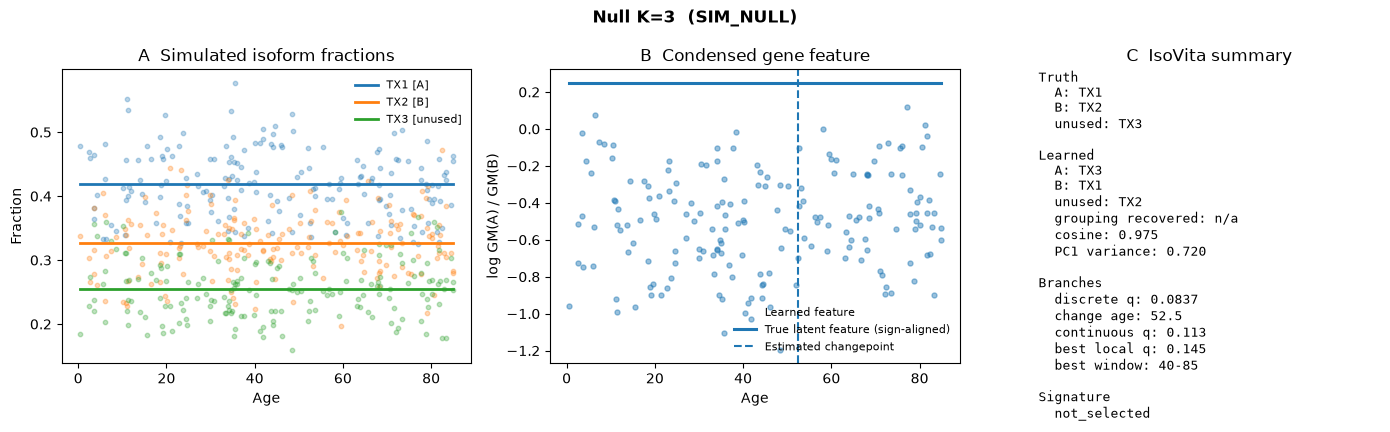

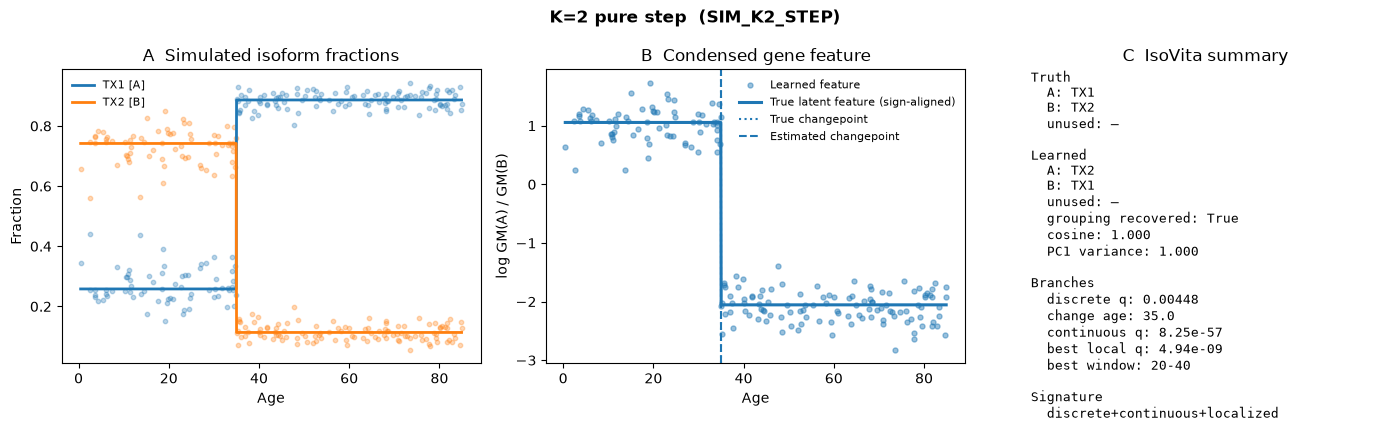

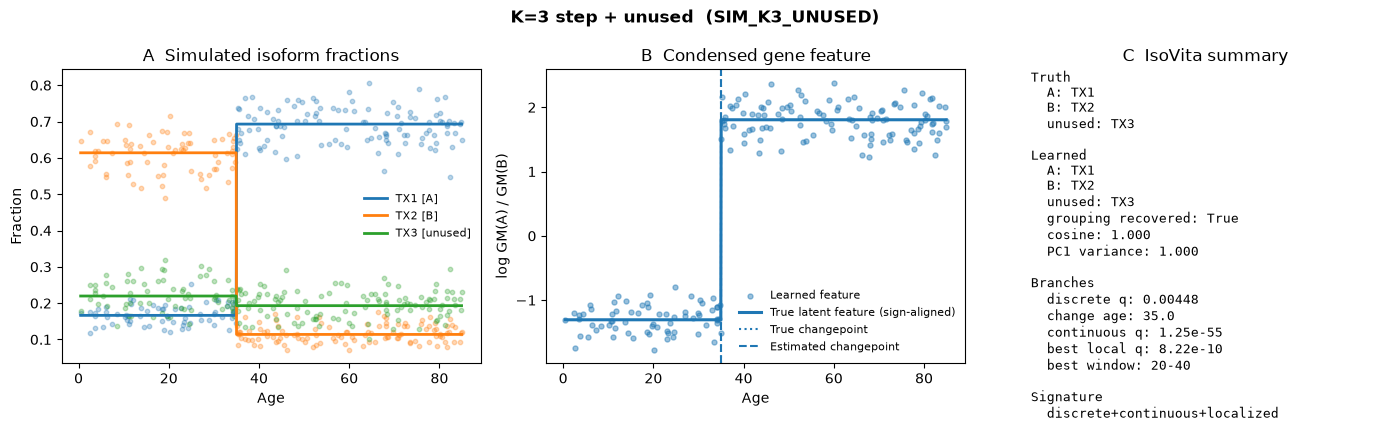

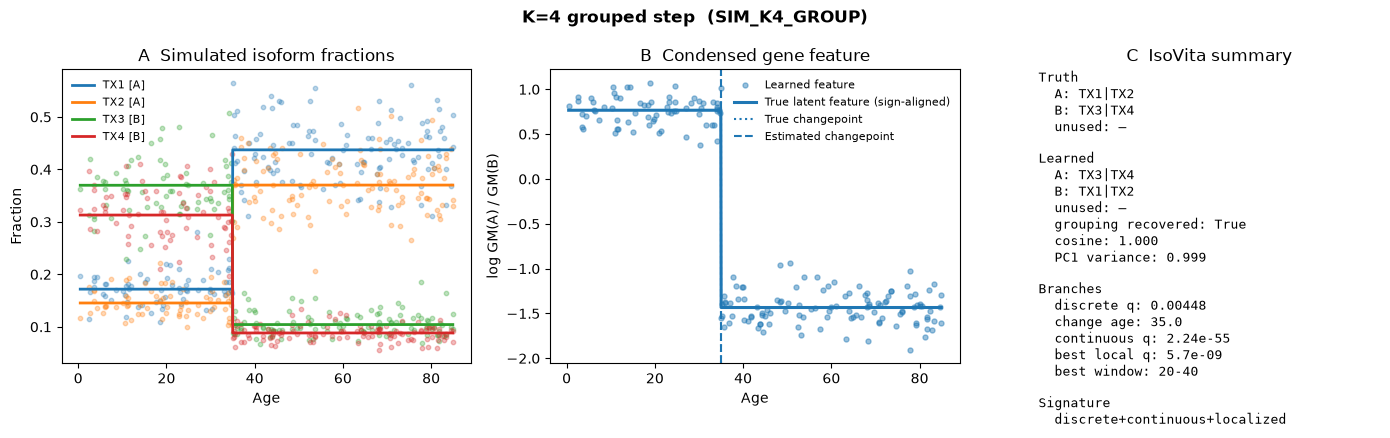

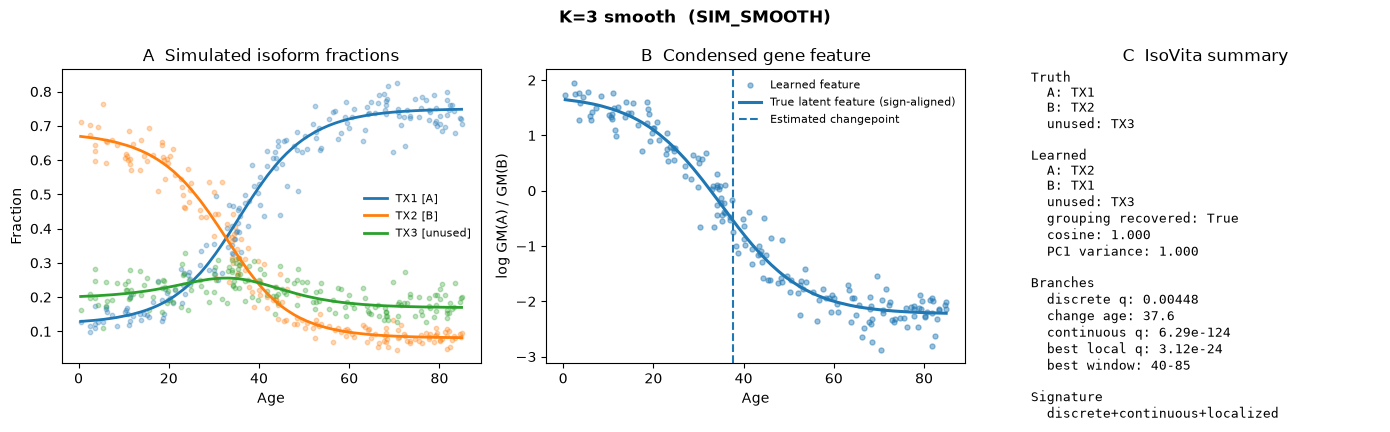

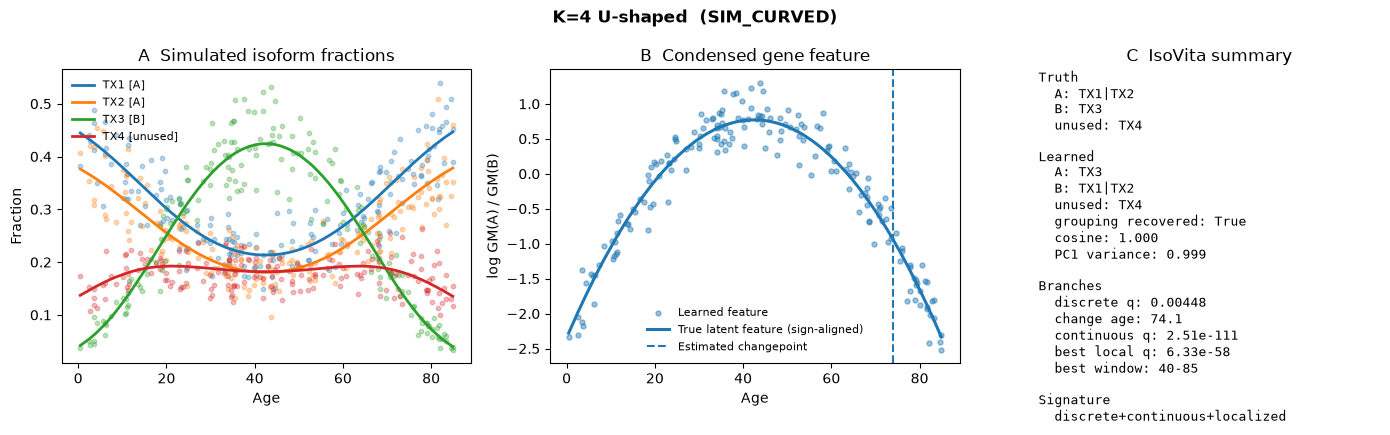

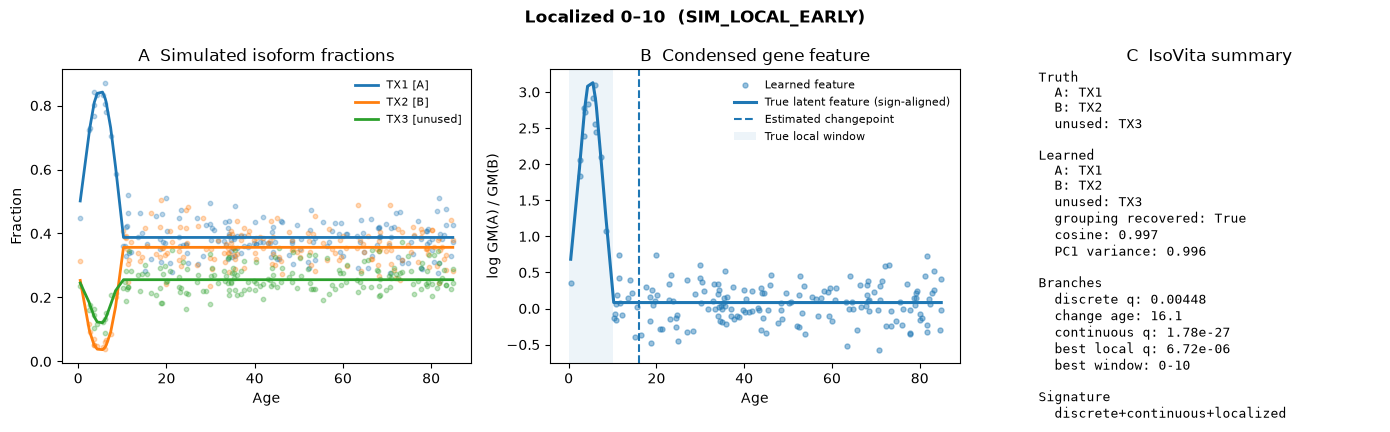

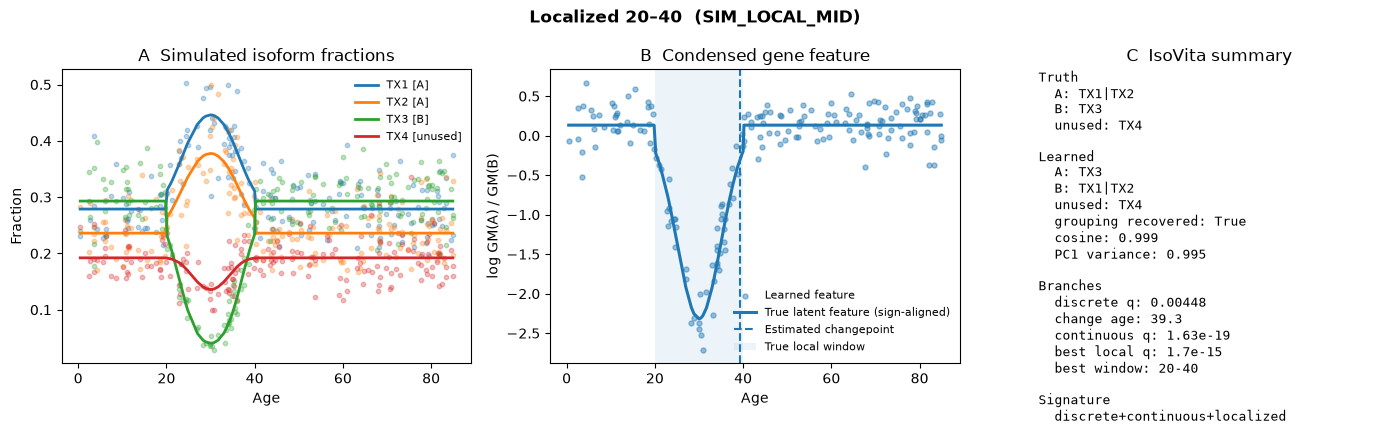

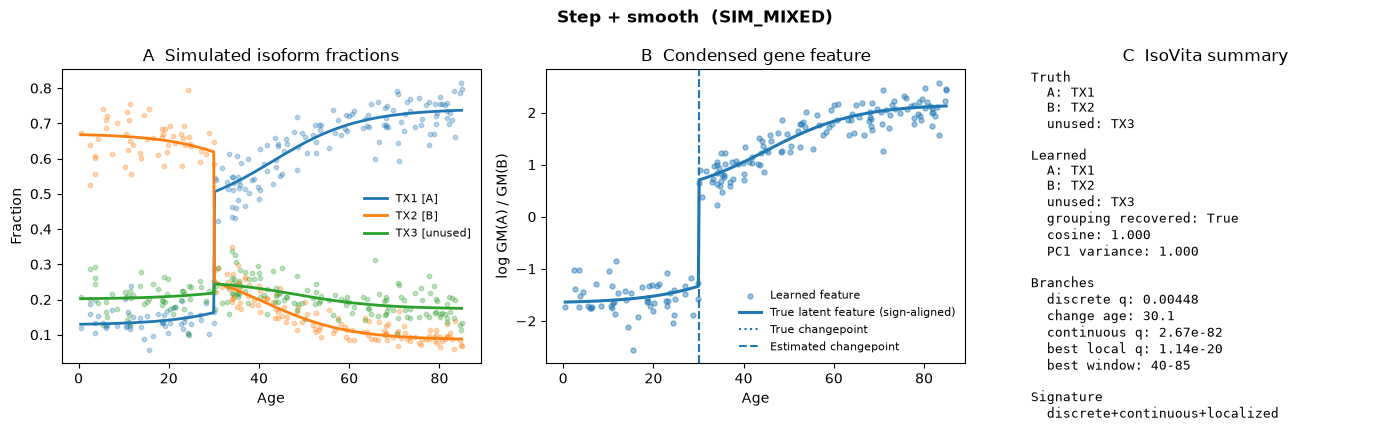

In [13]:
for scenario in SCENARIOS:
    plot_isovita_case(
        sim,
        result,
        scenario,
    )
    plt.show()